# Radial lens rectification from a measured photograph

## 1. Problem
Recover radial optical distortion and the rectified image from a photographed printed pattern. The scene contains straight physical edges, but the sensor observations curve. The goal is geometric recovery, not a synthetic image-degradation demonstration. Two observed line groups contain29 points. There is **no independently calibrated distortion GT or pristine same-scene image**: the original method output is a numerical reference only.

The selected AMI algebraic method jointly infers the two radial coefficients. It uses author-observed point geometry as calibration evidence; point coordinates do not encode fitted coefficients. Camera identity/exposure are unavailable and are not invented.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').is_dir():root=root.parent
assert (root/'data/raw_data.npz').is_file()
os.chdir(root);sys.path.insert(0,str(root))
from src.preprocessing import load_data,normalize_points,CENTER
from src.physics_model import determinant_polynomial,transform_points,rectify,straightness
from src.solvers import infer_distortion
from src.main import run
from src.visualization import line_residuals
data=load_data();points=data['line_points'];groups=data['line_ids']
with np.load('test/fixtures/upstream_stages.npz',allow_pickle=False) as f:original={k:f[k] for k in f.files}
plt.rcParams.update({'figure.dpi':110,'font.size':10})

## 2. Data
The complete688×506 RGB photograph is an actual camera image of a printed pattern. The paper calls this a “synthetic case” because the scene is a calibration pattern, then explicitly states that the pattern was printed and photographed. The bound archive supplies two edge groups(15+14 points); a separately linked one-line file is not the selected input. The full image retains processing, noise and exposure limitations of the author-distributed photograph. RGB intensities are digital codes, not calibrated radiance.

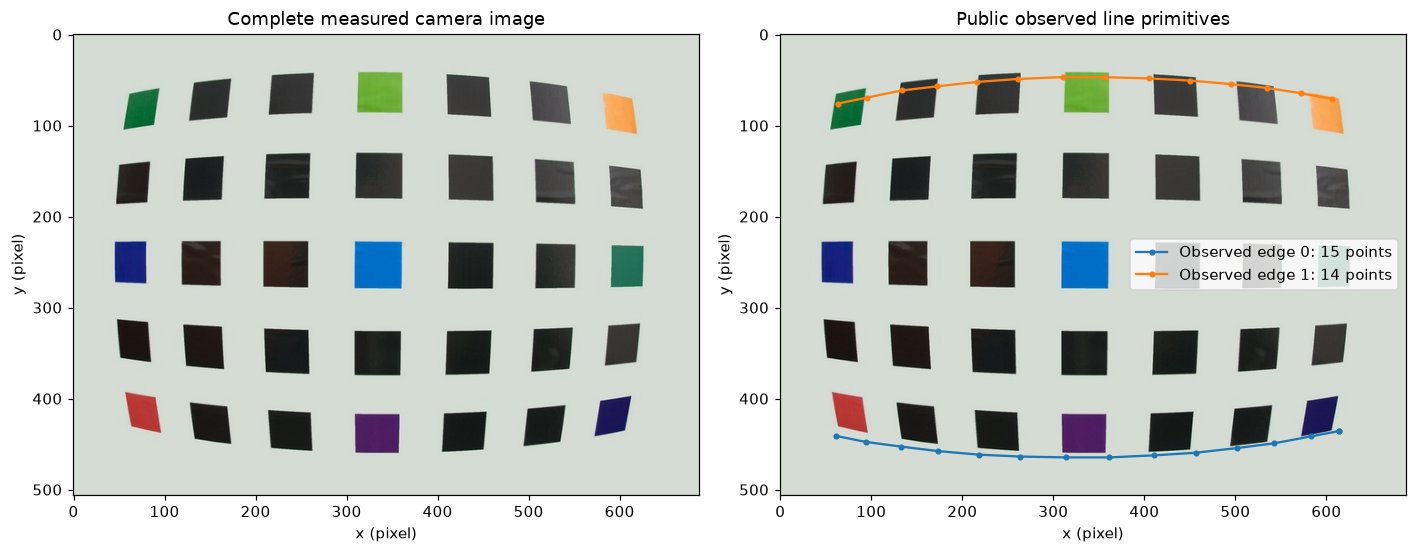

In [2]:
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
ax[0].imshow(data['image']);ax[0].set_title('Complete measured camera image')
ax[1].imshow(data['image'])
for k in np.unique(groups):
 p=points[groups==k];ax[1].plot(p[:,0],p[:,1],'.-',label=f'Observed edge {k}: {len(p)} points')
ax[1].set_title('Public observed line primitives');ax[1].legend()
for a in ax:a.set_xlabel('x (pixel)');a.set_ylabel('y (pixel)')
fig.tight_layout();plt.show()

## 3. Physics
For distorted coordinate $x$, center $c=(344,253)$ pixels and radius $r=\lVert x-c\rVert$, the corrected coordinate is
$$u=c+(1+k_2r^2+k_4r^4)(x-c).$$
The coefficients have units pixel⁻² and pixel⁻⁴. The corrected points on each edge should lie on an unknown straight line. Square pixels, radial symmetry and a fixed center are approximations; no scene-depth or tangential-aberration recovery is claimed.

At output pixel $v$, use $u=c+s(v-c)$, where $s=L(R)$ preserves the transformed source corners. Invert $rL(r)=\lVert u-c\rVert$ to sample the original image. The output has the same dimensions, with black exterior support. Intensity changes arise only from interpolation, not contrast enhancement.

## 4. Method
Normalize observed coordinates by their RMS radius $A$. Within each group, transformed coordinates depend affinely on two normalized coefficients. Their unnormalized scatter matrix $S$ gives the quartic objective
$$P(b_2,b_4)=\sum_{\ell}\det S_{\ell}(b_2,b_4).$$
Here $\ell$ indexes the two edges and $b_j=k_jA^j$. Explicit cubic derivatives, a6×6 Sylvester determinant and polynomial roots enumerate algebraic candidates. The minimum finite objective determines the coefficients; no generic reconstruction library is called. Original source uses RMS normalization with denominator N and unnormalized group scatter, differing from the paper's printed2N and normalized-covariance expressions. Those selected-code conventions are preserved and tested.

An independent constant-image test exposed integer roundoff in the original bilinear resampling:36,423 valid channel samples of a constant213 image became212. The local code returns the exact observed intensity for constant interpolation cells. This correction is explicitly disclosed; original reference arrays remain uncorrected. It does not change the inverse geometry or any acceptance threshold.

Fresh complete reconstruction seconds: 0.14984779997030273
Original coefficients: [1.00000000e+00 0.00000000e+00 9.98835040e-07 0.00000000e+00
 8.86985476e-12]
Fresh coefficients: [1.00000000e+00 0.00000000e+00 9.98834837e-07 0.00000000e+00
 8.86985597e-12]
Mean squared straightness before/after: 86.9141552425061 0.35251647388253515


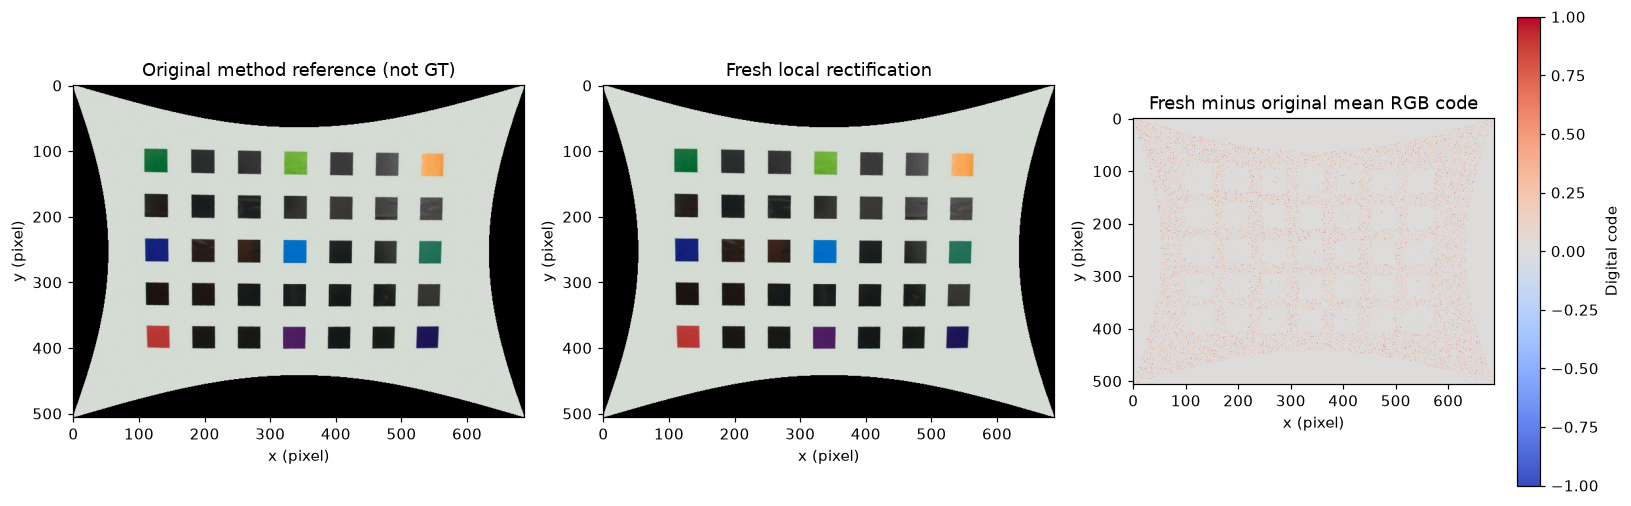

In [3]:
start=time.perf_counter();fresh=run();elapsed=time.perf_counter()-start
a=fresh['distortion'][0];reconstruction=fresh['reconstruction'][0]
mapped=transform_points(points,a)
print('Fresh complete reconstruction seconds:',elapsed)
print('Original coefficients:',original['distortion'])
print('Fresh coefficients:',a)
print('Mean squared straightness before/after:',straightness(points,groups),straightness(mapped,groups))
fig,axs=plt.subplots(1,3,figsize=(15,4.7))
axs[0].imshow(original['reconstruction']);axs[0].set_title('Original method reference (not GT)')
axs[1].imshow(reconstruction);axs[1].set_title('Fresh local rectification')
error=reconstruction.astype(float)-original['reconstruction'].astype(float)
im=axs[2].imshow(error.mean(axis=2),cmap='coolwarm',vmin=-1,vmax=1);axs[2].set_title('Fresh minus original mean RGB code')
fig.colorbar(im,ax=axs[2],label='Digital code')
for ax in axs:ax.set_xlabel('x (pixel)');ax.set_ylabel('y (pixel)')
fig.tight_layout();plt.show()

## 5. Results
All results below use a fresh local inversion. The full image comparison tests implementation consistency; it cannot certify unknown camera geometry. Straight-edge residuals independently assess the physical line constraint. A fixed central scale is necessary because arbitrary scaling could collapse the covariance objective. The supplied geometry uses the original scale convention, not post-hoc alignment to a reference.

{
  "ncc": 0.9999995951406144,
  "nrmse": 0.000613661737091073,
  "coefficient_relative": 2.0256876742674734e-07,
  "gauge_error": 0.0,
  "odd_coefficient": 0.0
}


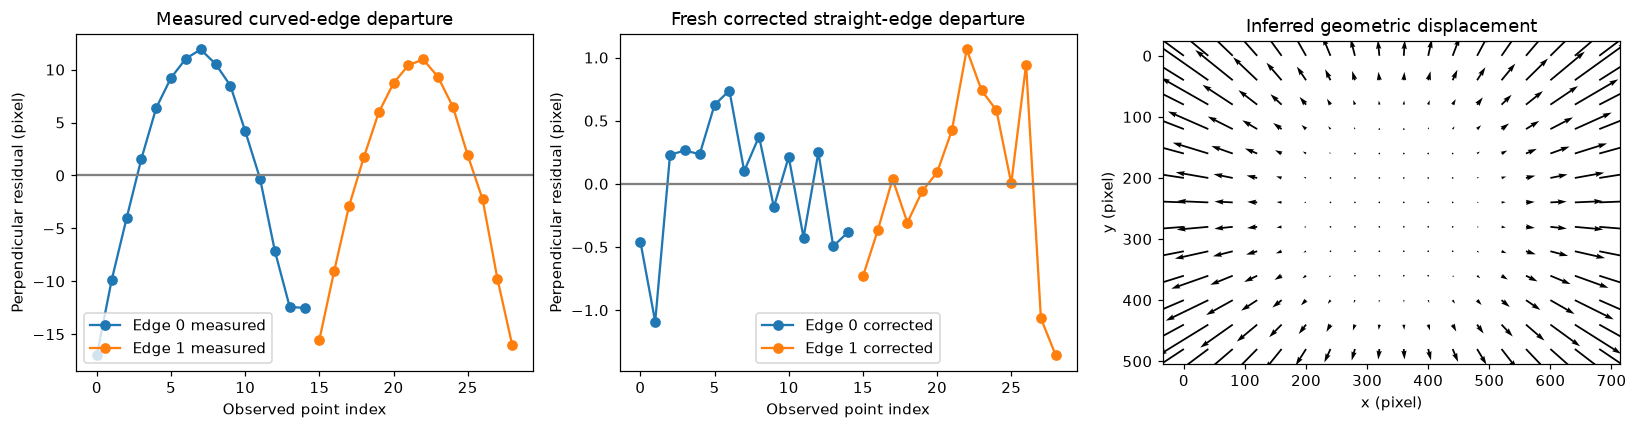

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('review_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,status=judge.evaluate(root/'output/reconstruction.npz');assert status==0
print(json.dumps(report['metrics'],indent=2))
fig,axs=plt.subplots(1,3,figsize=(15,4))
before=line_residuals(points,groups);after=line_residuals(mapped,groups)
for k in np.unique(groups):
 ids=np.flatnonzero(groups==k)
 axs[0].plot(ids,before[ids],'o-',label=f'Edge {k} measured')
 axs[1].plot(ids,after[ids],'o-',label=f'Edge {k} corrected')
for ax in axs[:2]:ax.axhline(0,color='gray');ax.set_xlabel('Observed point index');ax.set_ylabel('Perpendicular residual (pixel)');ax.legend()
axs[0].set_title('Measured curved-edge departure');axs[1].set_title('Fresh corrected straight-edge departure')
grid=np.stack(np.meshgrid(np.arange(0,688,40),np.arange(0,506,40)),axis=-1).reshape(-1,2)
delta=transform_points(grid,a)-grid
axs[2].quiver(grid[:,0],grid[:,1],delta[:,0],delta[:,1],angles='xy',scale_units='xy',scale=1)
axs[2].invert_yaxis();axs[2].set_aspect('equal');axs[2].set_title('Inferred geometric displacement');axs[2].set_xlabel('x (pixel)');axs[2].set_ylabel('y (pixel)')
fig.tight_layout();plt.show()

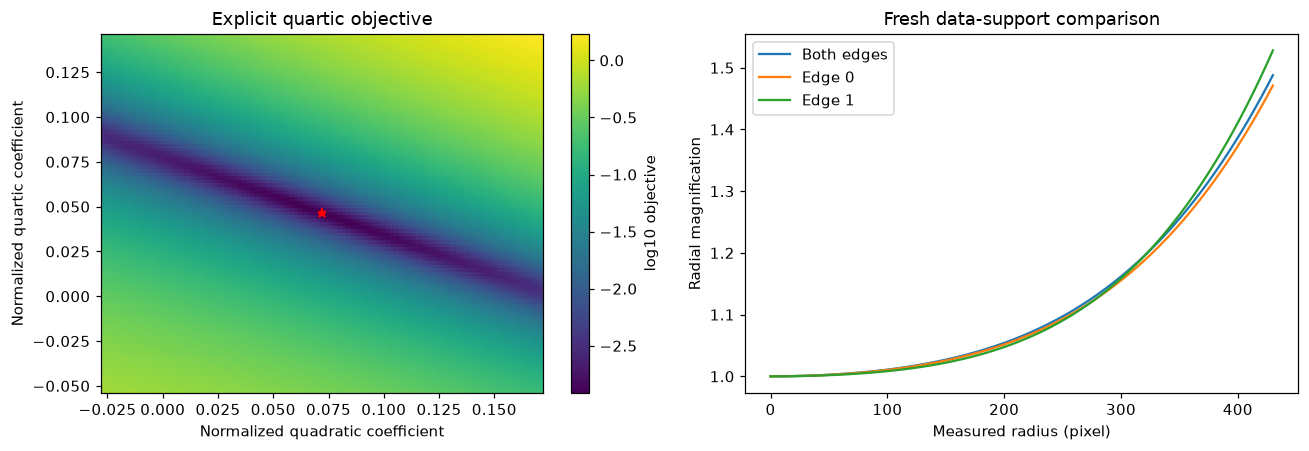

In [5]:
normalized,factor=normalize_points(points);polynomial=determinant_polynomial(normalized,groups)
bx=a[2]*factor**2;by=a[4]*factor**4
gx=np.linspace(bx-.1,bx+.1,101);gy=np.linspace(by-.1,by+.1,101);xx,yy=np.meshgrid(gx,gy)
objective=np.polynomial.polynomial.polyval2d(xx,yy,polynomial)
fig,axs=plt.subplots(1,2,figsize=(12,4.2))
im=axs[0].imshow(np.log10(np.maximum(objective,1e-16)),origin='lower',extent=[gx[0],gx[-1],gy[0],gy[-1]],aspect='auto',cmap='viridis')
axs[0].plot(bx,by,'r*');axs[0].set_xlabel('Normalized quadratic coefficient');axs[0].set_ylabel('Normalized quartic coefficient');axs[0].set_title('Explicit quartic objective');fig.colorbar(im,ax=axs[0],label='log10 objective')
single=[]
for k in np.unique(groups):
 mask=groups==k
 try:
  fit=infer_distortion(points[mask],groups[mask]);single.append((f'Edge {k}',fit))
 except Exception as exc:print('Single-edge diagnostic failed:',k,str(exc))
radius=np.linspace(0,430,300)
for label,fit in [('Both edges',a)]+single:axs[1].plot(radius,np.polynomial.polynomial.polyval(radius,fit),label=label)
axs[1].set_xlabel('Measured radius (pixel)');axs[1].set_ylabel('Radial magnification');axs[1].set_title('Fresh data-support comparison');axs[1].legend()
fig.tight_layout();plt.show()

### Sensitivity and limitations
The following point-coordinate perturbations are supplementary synthetic diagnostics on a fixed real image. They are not additional real acquisitions or measured localization uncertainties. Each trial reruns the algebraic inverse; failed candidates are reported explicitly. Single-edge extrapolation and correlated coefficient variability illustrate why low residuals on a few lines do not establish global geometric truth.

Failed optional algebraic trials: []
Non-invertible optional candidates (not successful rectifications): 4


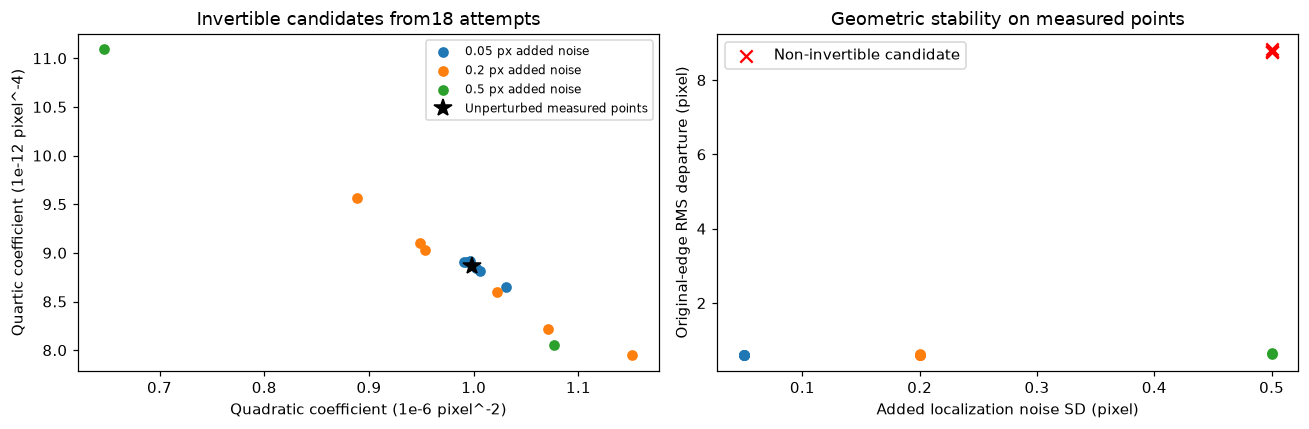

2686

In [6]:
rng=np.random.default_rng(27);trials=[];failures=[]
for sigma in [.05,.2,.5]:
 for rep in range(6):
  try:
   fit=infer_distortion(points+rng.normal(0,sigma,points.shape),groups)
   rr=np.linspace(0,430,2001)
   minimum_slope=np.min(1+3*fit[2]*rr**2+5*fit[4]*rr**4)
   trials.append([sigma,fit[2],fit[4],straightness(transform_points(points,fit),groups),minimum_slope])
  except Exception as exc:failures.append([sigma,rep,str(exc)])
trials=np.array(trials);print('Failed optional algebraic trials:',failures)
invalid=trials[:,4]<=0
print('Non-invertible optional candidates (not successful rectifications):',int(invalid.sum()))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for sigma in [.05,.2,.5]:
 mask=(trials[:,0]==sigma)&~invalid
 axs[0].scatter(trials[mask,1]*1e6,trials[mask,2]*1e12,label=f'{sigma} px added noise')
 axs[1].scatter(trials[mask,0],np.sqrt(trials[mask,3]))
axs[0].plot(a[2]*1e6,a[4]*1e12,'k*',markersize=12,label='Unperturbed measured points')
axs[0].set_xlabel('Quadratic coefficient (1e-6 pixel^-2)');axs[0].set_ylabel('Quartic coefficient (1e-12 pixel^-4)');axs[0].legend(fontsize=8);axs[0].set_title('Invertible candidates from18 attempts')
if invalid.any():
 axs[1].scatter(trials[invalid,0],np.sqrt(trials[invalid,3]),marker='x',s=65,c='red',label='Non-invertible candidate');axs[1].legend()
axs[1].set_xlabel('Added localization noise SD (pixel)');axs[1].set_ylabel('Original-edge RMS departure (pixel)');axs[1].set_title('Geometric stability on measured points')
fig.tight_layout();plt.show()
measurements={'runtime_seconds':elapsed,'metrics':report['metrics'],'coefficients':a.tolist(),'straightness_before':straightness(points,groups),'straightness_after':straightness(mapped,groups),'synthetic_trials':trials.tolist(),'failed_trials':failures}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurements,indent=2,allow_nan=False),encoding='utf8')

## 6. Conclusion
The complete measured photograph is rectified by an explicitly implemented algebraic geometric inverse. Independent original-stage comparisons test the quartic, recovered coefficients, transformed points and full image; mathematical tests check scatter expansion, inverse-radius consistency and constant-image preservation. The fresh estimate is evaluated jointly in image and coefficient space.

Limitations remain: two finite edges cannot reveal arbitrary optical aberration, the center is fixed rather than independently calibrated, the image is author-processed RGB, and no true undistorted camera image exists. The disclosed constant-cell numerical correction explains why original and fresh images need not be bit-identical. The objective and sensitivity figures expose geometric ambiguity rather than concealing it.

Paper: Alvarez,Gomez,Sendra, *Algebraic Lens Distortion Model Estimation*, IPOL2010, DOI10.5201/ipol.2010.ags-alde. Exact original code revision, data hashes, licenses, execution records and deviations are in `test/validation.md`.